# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

braki:           braki    procent
Cabin       687  77.104377
Age         177  19.865320
Embarked      2   0.224467


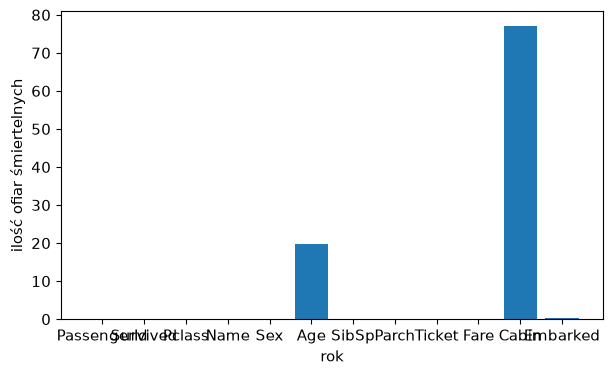

In [9]:
# TODO
# 1.
braki = titanic.isna().sum()

kolumny = pd.DataFrame({
    "braki": braki,
    "procent": titanic.isna().mean() * 100
})
print("braki:", kolumny[kolumny["braki"] > 0].sort_values("procent", ascending=False))

# 2.
plt.bar(kolumny.index, kolumny["procent"])
plt.xlabel("rok")
plt.ylabel("ilość ofiar śmiertelnych")
plt.show()


### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

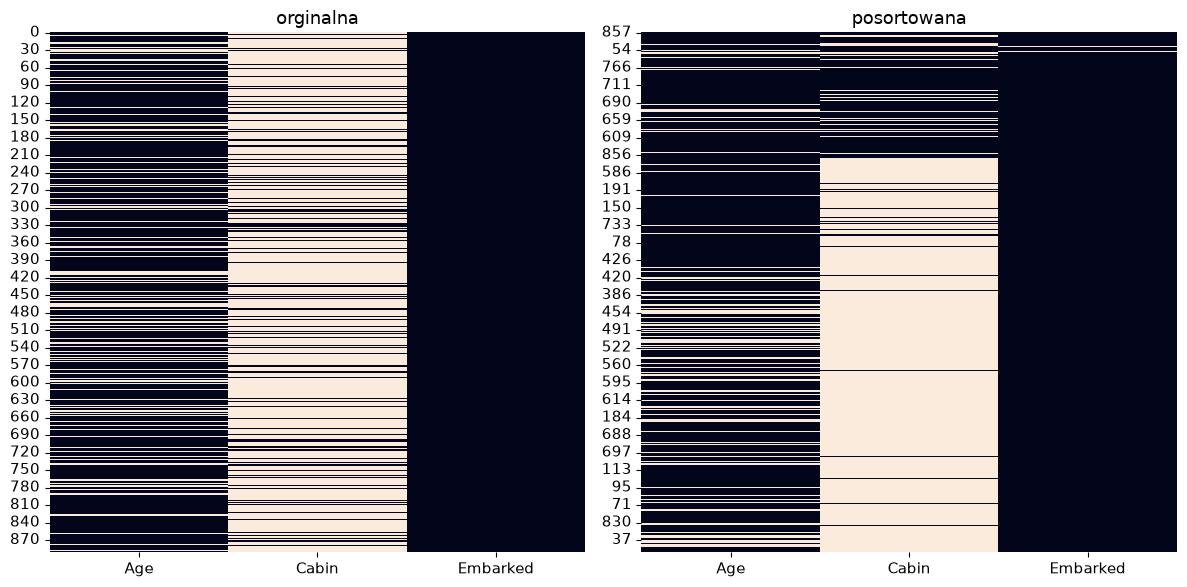

In [10]:
kolumny = ["Age", "Cabin", "Embarked"]

# TODO
fig, osie = plt.subplots(1, 2, figsize=(12, 6))

sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=osie[0])
osie[0].set_title("orginalna")

posortowane = titanic.sort_values("Pclass")
# print("sortowane:", posortowane)
sns.heatmap(posortowane[kolumny].isna(), cbar=False)
osie[1].set_title("posortowana")

plt.tight_layout()
plt.show()


*Twoja odpowiedź:* …
Braki są nierównomierne. Widać małe zagęszczenie w pierwszej klasie.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

braki w klasie:
 Pclass
1    13.888889
2     5.978261
3    27.698574
Name: Age, dtype: float64
braki w płci:
 Sex
female    16.878981
male      21.490468
Name: Age, dtype: float64
ocalali:
 znany wiek        40.616246
nie znany wiek    29.378531
Name: Survived, dtype: float64


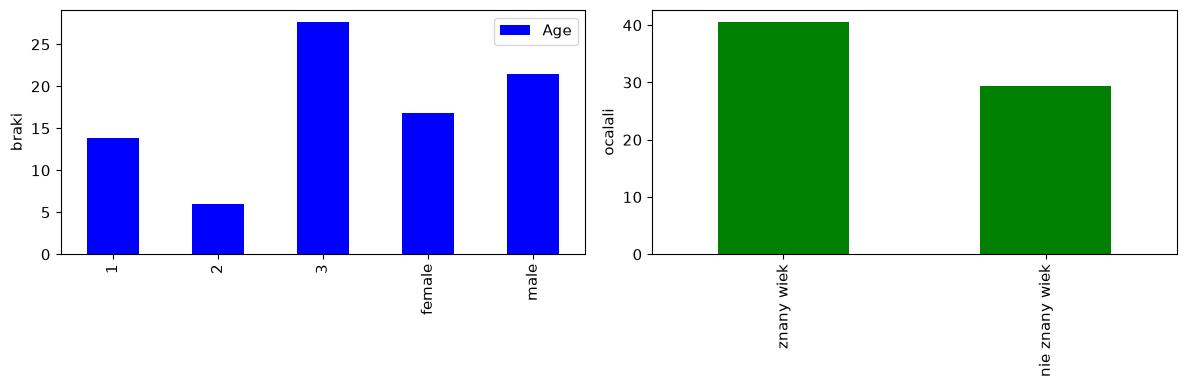

In [11]:
# 1.?
brak_wieku = titanic["Age"].isna()

# TODO
# 2.
braki_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
print("braki w klasie:\n", braki_klasa)
braki_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100
print("braki w płci:\n", braki_plec)

# 3.
ocalali = titanic.groupby(brak_wieku)["Survived"].mean() * 100
ocalali.index = ["znany wiek", "nie znany wiek"]
print("ocalali:\n", ocalali)

# 4.
fig, osie = plt.subplots(1, 2, figsize=(12, 4))
pd.concat([braki_klasa, braki_plec]).plot.bar(ax=osie[0], color="blue")
osie[0].set_ylabel("braki")
osie[0].legend()

# Wykres 2 - przeżywalność
ocalali.plot.bar(ax=osie[1], color="green")
osie[1].set_ylabel("ocalali")

plt.tight_layout()
plt.show()


*Twoja odpowiedź:* …   
Są różnice więc to prawdopodobnie nie jest MCAR, który jest całkowicie losowy.  
Gdybyśmy usuneli wiersze z nieznanym wiekiem dla ocalałych, wtedy ilość ocalałbych byłaby większa niż powinna.


### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [15]:
warianty = {
    "bez zmian": titanic,
    "titanicEmbarked": titanic.dropna(subset=["Embarked"]),
    "titanicAge": titanic.dropna(subset=["Age"]),
    "titanicDropna": titanic.dropna()
}

# TODO: tabela
doTabeli = []
for nazwa, dane in warianty.items():
    doTabeli.append({
        "typ": nazwa,
        "liczba wierszy": len(dane),
        "odsetek ocalałych": dane["Survived"].mean() * 100,
        "odsetek 1 klasy:": (dane["Pclass"] == 1).mean() * 100
    })

tabela = pd.DataFrame(doTabeli)
print("tabela:\n", tabela)

tabela:
                typ  liczba wierszy  odsetek ocalałych  odsetek 1 klasy:
0        bez zmian             891          38.383838         24.242424
1  titanicEmbarked             889          38.245219         24.071991
2       titanicAge             714          40.616246         26.050420
3    titanicDropna             183          67.213115         86.338798


*Twoja odpowiedź:* …  
Najbardziej zniekształca dane zwykłe "dropna" bez argumentów, jest to z powodu usunięcia całego wiersza danych, gdy tylko jedna wartość ma brakujące dane, podczas gdy pozostałe dane usuwają wiersze tylko gdy brakuje wartości w age, lub embarked

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Age brak:
 Age_brak
False    714
True     177
Name: count, dtype: int64
mediany w grupach:
 Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64
braki po uzupełnieniu: 0 0


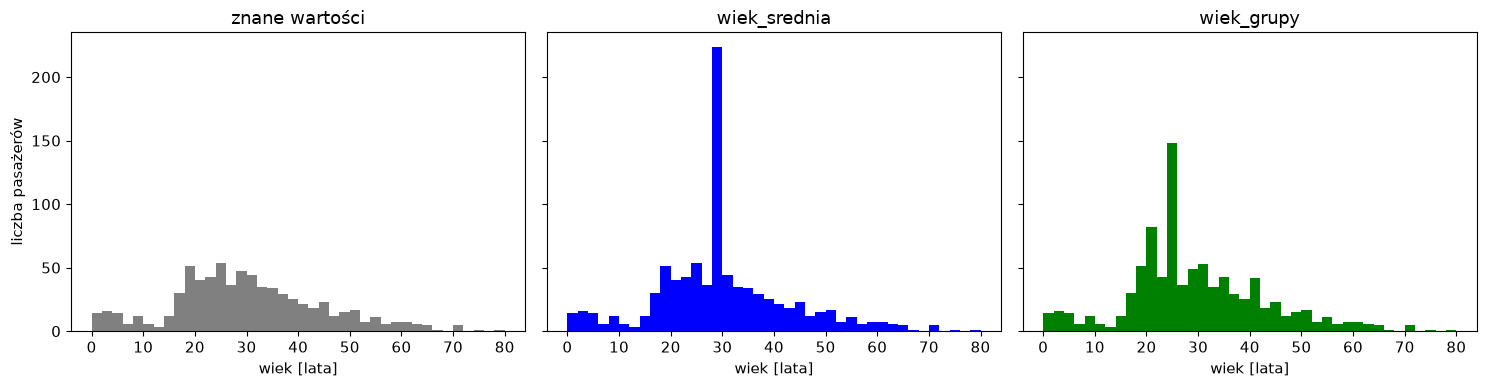

odchylenia standardowe:
 znane wartości    14.526497
wiek_srednia      13.002015
wiek_grupy        13.304424
dtype: float64


In [16]:
# TODO
# 1.
titanic["Age_brak"] = titanic["Age"].isna()
print("Age brak:\n", titanic["Age_brak"].value_counts())

# 2.
titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
mediany_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediany_grup)
print("mediany w grupach:\n", titanic.groupby(["Pclass", "Sex"])["Age"].median())
print("braki po uzupełnieniu:", titanic["wiek_srednia"].isna().sum(), titanic["wiek_grupy"].isna().sum())

# 3.
przedzialy = np.arange(0, 82, 2)
fig, osie = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

osie[0].hist(titanic["Age"].dropna(), bins=przedzialy, color="gray")
osie[0].set_title("znane wartości")

osie[1].hist(titanic["wiek_srednia"], bins=przedzialy, color="blue")
osie[1].set_title("wiek_srednia")

osie[2].hist(titanic["wiek_grupy"], bins=przedzialy, color="green")
osie[2].set_title("wiek_grupy")

for ax in osie:
    ax.set_xlabel("wiek [lata]")
osie[0].set_ylabel("liczba pasażerów")

plt.tight_layout()
plt.show()

# 4.
odchylenia = pd.Series({
    "znane wartości": titanic["Age"].std(),
    "wiek_srednia": titanic["wiek_srednia"].std(),
    "wiek_grupy": titanic["wiek_grupy"].std()
})
print("odchylenia standardowe:\n", odchylenia)

*Twoja odpowiedź:* …
Bardziej zniekształca rozkład uzupełnianie średnią — wszystkie 177 braków trafia do jednego słupka (ok. 29,7 roku), przez co na histogramie powstaje sztuczny pik, a odchylenie standardowe spada z ok. 14,5 do ok. 13,0.
Mediana w grupach (klasa × płeć) rozkłada braki na kilka różnych wartości, więc rozkład wygląda bardziej naturalnie, a odchylenie standardowe (ok. 13,3) jest bliżej oryginalnego.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

najmniejszy i największy uzupełniony wiek: -7.348648995424419 42.02286213226965


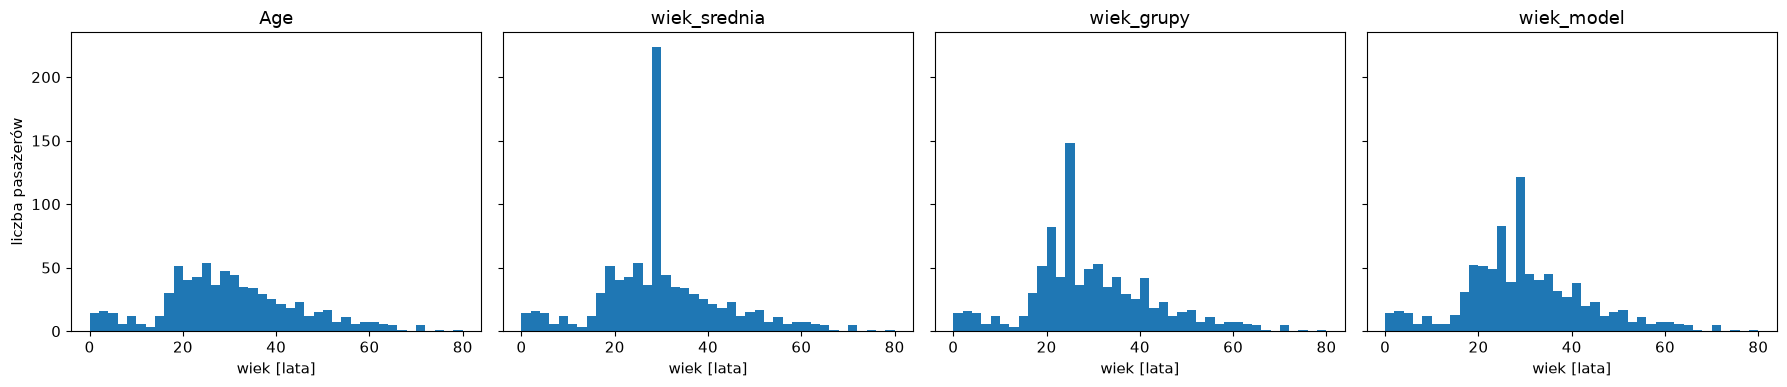

odchylenia standardowe:
 znane wartości    14.526497
wiek_srednia      13.002015
wiek_grupy        13.304424
wiek_model        13.637037
dtype: float64


In [17]:
# TODO
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

dane_modelu = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
dane_modelu["plec"] = (titanic["Sex"] == "female").astype(int)

imputer = IterativeImputer(random_state=0)
wynik = imputer.fit_transform(dane_modelu)
titanic["wiek_model"] = wynik[:, 0]
print("najmniejszy i największy uzupełniony wiek:",
      titanic.loc[titanic["Age_brak"], "wiek_model"].min(),
      titanic.loc[titanic["Age_brak"], "wiek_model"].max())

fig, osie = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, kolumna in zip(osie, ["Age", "wiek_srednia", "wiek_grupy", "wiek_model"]):
    ax.hist(titanic[kolumna].dropna(), bins=przedzialy)
    ax.set_title(kolumna)
    ax.set_xlabel("wiek [lata]")
osie[0].set_ylabel("liczba pasażerów")
plt.tight_layout()
plt.show()

odchylenia["wiek_model"] = titanic["wiek_model"].std()
print("odchylenia standardowe:\n", odchylenia)

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [18]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# TODO
# 1.
print("typy:\n", mieszkania.dtypes)

# 2.
print("braki:\n", mieszkania.isna().sum())
print("razem braków:", mieszkania.isna().sum().sum())

# 3.
print("wartości powierzchni:", mieszkania["powierzchnia"].unique().tolist())

typy:
 id               int64
miasto             str
dzielnica          str
powierzchnia       str
liczba_pokoi     int64
rok_budowy         str
pietro             str
liczba_pieter    int64
parking            str
balkon             str
stan               str
cena_m2          int64
cena_total       int64
dtype: object
braki:
 id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
razem braków: 8
wartości powierzchni: ['65', '48', '72', '55', '80', nan, '60', '45', '70', '90', '58', '52', '68', '0', '75', '62', '50', 'brak', '66', '85', '54', '95', '56', '42', '78', '88', '64', '51', '69', '46', '82', '76']


*Twoja odpowiedź:* …
Pandas widzi tylko 8 braków (4 w `powierzchnia` zapisane jako `N/A` i 4 w `rok_budowy` zapisane jako `NA`) — to są domyślne oznaczenia braków.
Kolumna `powierzchnia` nie jest liczbowa, bo oprócz liczb ma też tekst `brak`; jedna wartość tekstowa sprawia, że cała kolumna wczytuje się jako tekst. Tak samo jest z `rok_budowy` i `pietro`.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [22]:
# TODO 1
for kolumna in mieszkania.columns.drop(["id", "dzielnica", "cena_total"]):
    print("kolumna:", kolumna)
    print(mieszkania[kolumna].value_counts(dropna=False).sort_index().to_dict())

print("cena_total min/max:", mieszkania["cena_total"].min(), mieszkania["cena_total"].max())

kolumna: miasto
{'Gdańsk': 9, 'Kraków': 9, 'Poznań': 9, 'Warszawa': 9, 'Wrocław': 9}
kolumna: powierzchnia
{42.0: 1, 45.0: 1, 46.0: 1, 48.0: 2, 50.0: 1, 51.0: 1, 52.0: 1, 54.0: 1, 55.0: 2, 56.0: 1, 58.0: 2, 60.0: 2, 62.0: 2, 64.0: 1, 65.0: 1, 66.0: 1, 68.0: 1, 69.0: 1, 70.0: 2, 72.0: 2, 75.0: 1, 76.0: 1, 78.0: 1, 80.0: 1, 82.0: 1, 85.0: 1, 88.0: 1, 90.0: 1, 95.0: 1, nan: 9}
kolumna: liczba_pokoi
{1: 4, 2: 15, 3: 18, 4: 7, 5: 1}
kolumna: rok_budowy
{1995.0: 1, 1996.0: 1, 1997.0: 1, 1998.0: 1, 1999.0: 1, 2000.0: 1, 2001.0: 1, 2002.0: 1, 2003.0: 1, 2004.0: 1, 2005.0: 1, 2006.0: 1, 2007.0: 1, 2008.0: 1, 2009.0: 1, 2010.0: 2, 2011.0: 2, 2012.0: 1, 2013.0: 2, 2014.0: 2, 2015.0: 2, 2016.0: 2, 2017.0: 2, 2018.0: 2, 2019.0: 2, 2020.0: 2, 2021.0: 1, 2022.0: 1, nan: 7}
kolumna: pietro
{0.0: 3, 1.0: 8, 2.0: 9, 3.0: 7, 4.0: 6, 5.0: 3, 6.0: 3, 7.0: 2, 8.0: 1, nan: 3}
kolumna: liczba_pieter
{2: 2, 3: 3, 4: 7, 5: 6, 6: 4, 7: 4, 8: 5, 9: 4, 10: 4, 11: 3, 12: 2, 15: 1}
kolumna: parking
{'Nie': 6, 'Tak':

*Twoja odpowiedź:* …
1. Wartości oznaczające brak: `N/A`, `brak`, `0`, `-999`, `?`, `-1`, `很好` - jest według tłumacza google "bardzo dobry" więc pasuje i nie jest brakiem
2. w `powierzchnia` 0 to raczej brak danych bo nie ma sensu, ale na `piętro` jest to prawdopodobnie oznaczenie parteru.

In [20]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    # TODO: pozostałe kolumny
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
# TODO: typy i liczba braków
print("typy:\n", mieszkania.dtypes)
print("braki:\n", mieszkania.isna().sum())
print("razem braków:", mieszkania.isna().sum().sum())

typy:
 id                 int64
miasto               str
dzielnica            str
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking              str
balkon               str
stan                 str
cena_m2          float64
cena_total         int64
dtype: object
braki:
 id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64
razem braków: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [24]:
# TODO
print("stan przed:\n", mieszkania["stan"].value_counts())
print(mieszkania[mieszkania["stan"] == "很好"])

mieszkania["stan"] = mieszkania["stan"].replace({"很好": "bardzo dobry"})
print("stan po:\n", mieszkania["stan"].value_counts())

stan przed:
 stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64
Empty DataFrame
Columns: [id, miasto, dzielnica, powierzchnia, liczba_pokoi, rok_budowy, pietro, liczba_pieter, parking, balkon, stan, cena_m2, cena_total]
Index: []
stan po:
 stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


*Twoja odpowiedź:* …
`很好` to po chińsku "bardzo dobrze", ale nie pausje do standardu języka, dlatego należałoby zmienic to aby pasowało do reszty.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

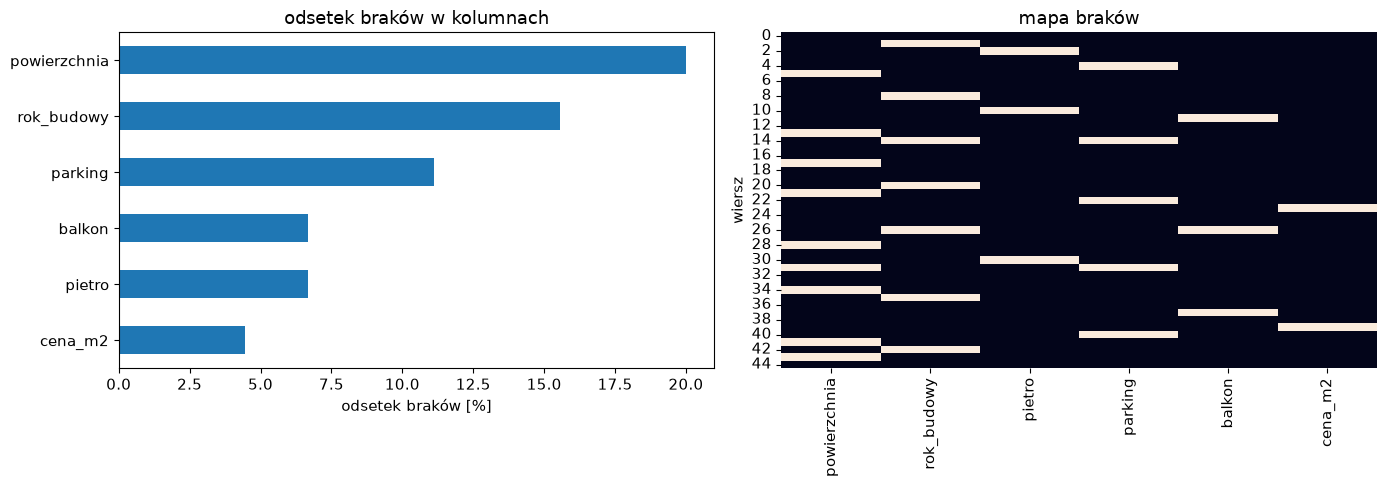

korelacja braków:
               powierzchnia  rok_budowy  pietro  parking  balkon  cena_m2
powierzchnia          1.00       -0.21   -0.13    -0.00   -0.13    -0.11
rok_budowy           -0.21        1.00   -0.11     0.04    0.13    -0.09
pietro               -0.13       -0.11    1.00    -0.09   -0.07    -0.06
parking              -0.00        0.04   -0.09     1.00   -0.09    -0.08
balkon               -0.13        0.13   -0.07    -0.09    1.00    -0.06
cena_m2              -0.11       -0.09   -0.06    -0.08   -0.06     1.00
wiersze z więcej niż jednym brakiem: 3


In [25]:
# TODO
# 1.
z_brakami = mieszkania.columns[mieszkania.isna().any()]
procent_brakow = mieszkania[z_brakami].isna().mean().sort_values() * 100

fig, osie = plt.subplots(1, 2, figsize=(14, 5))

procent_brakow.plot.barh(ax=osie[0])
osie[0].set_xlabel("odsetek braków [%]")
osie[0].set_title("odsetek braków w kolumnach")

sns.heatmap(mieszkania[z_brakami].isna(), cbar=False, ax=osie[1])
osie[1].set_title("mapa braków")
osie[1].set_ylabel("wiersz")

plt.tight_layout()
plt.show()

# 2.
print("korelacja braków:\n", mieszkania[z_brakami].isna().corr().round(2))
print("wiersze z więcej niż jednym brakiem:", (mieszkania.isna().sum(axis=1) > 1).sum())

*Twoja odpowiedź:* …  
Nie. Korelacje braków między kolumnami są bliskie zera (najwyżej ok. ±0,2), a tylko 3 wiersze mają więcej niż jeden brak (maksymalnie 2). Braki są rozrzucone po różnych wierszach, więc zwykłe `dropna()` wyrzuciłoby aż 26 z 45 mieszkań.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [ ]:
# TODO
pelne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
roznica = (pelne["powierzchnia"] * pelne["cena_m2"] - pelne["cena_total"]).abs()
print("największa różnica:", roznica.max())

braki_przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()

mieszkania["powierzchnia_brak"] = mieszkania["powierzchnia"].isna()
mieszkania["cena_m2_brak"] = mieszkania["cena_m2"].isna()

mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(
    (mieszkania["cena_total"] / mieszkania["cena_m2"]).round()
)
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(
    (mieszkania["cena_total"] / mieszkania["powierzchnia"]).round()
)

braki_po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
print("braki przed:\n", braki_przed)
print("braki po:\n", braki_po)
print("odtworzono:", (braki_przed - braki_po).sum())
print(mieszkania.loc[mieszkania["powierzchnia_brak"] | mieszkania["cena_m2_brak"], ["id", "powierzchnia", "cena_m2", "cena_total"]])

największa różnica: 0.0
braki przed:
 powierzchnia    9
cena_m2         2
dtype: int64
braki po:
 powierzchnia    0
cena_m2         0
dtype: int64
odtworzono: 11
    id  powierzchnia  cena_m2  cena_total
5    6          80.0  15000.0     1200000
13  14          60.0  10800.0      648000
17  18          70.0   9200.0      644000
21  22          60.0   9800.0      588000
23  24          48.0  12500.0      600000
28  29          60.0  10200.0      612000
31  32          60.0   9400.0      564000
34  35          80.0   8800.0      704000
39  40          82.0   8895.0      729400
41  42          60.0   9200.0      552000
43  44          65.0   9500.0      617500


*Twoja odpowiedź:* …
Dla wszystkich wierszy bez braków `cena_total = powierzchnia × cena_m2` zgadza się co do złotówki, więc odtworzyłem wszystkie 11 braków (9 w `powierzchnia` i 2 w `cena_m2`). Jedynie dla mieszkania 40 cena za m² nie wychodzi równa (729400 / 82 ≈ 8895), więc zaokrągliłem ją do pełnych złotych.

### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [27]:
# TODO
# 1.
for kolumna in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[kolumna + "_brak"] = mieszkania[kolumna].isna()

# 2.
# rok_budowy
print("mediana całościowa:", mieszkania["rok_budowy"].median())
print("mediana wg miasta:\n", mieszkania.groupby("miasto")["rok_budowy"].median())
print("mediana wg stanu:\n", mieszkania.groupby("stan")["rok_budowy"].median())

mediana_stan = mieszkania.groupby("stan")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_stan)

# pietro
print("braki piętra:\n", mieszkania.loc[mieszkania["pietro_brak"], ["id", "pietro", "liczba_pieter"]])
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)

# parking, balkon
for kolumna in ["parking", "balkon"]:
    dominanta = mieszkania[kolumna].fillna(mieszkania[kolumna].mode()[0])
    nieznane = mieszkania[kolumna].fillna("nieznane")
    print(kolumna, "- odsetek 'Tak':",
          "bez braków:", round((mieszkania[kolumna].dropna() == "Tak").mean() * 100, 1),
          "dominanta:", round((dominanta == "Tak").mean() * 100, 1),
          "nieznane:", round((nieznane == "Tak").mean() * 100, 1))
    mieszkania[kolumna] = nieznane

# 3.
print("braki:\n", mieszkania.isna().sum())
print("razem braków:", mieszkania.isna().sum().sum())

mediana całościowa: 2011.5
mediana wg miasta:
 miasto
Gdańsk      2001.5
Kraków      2013.0
Poznań      2013.5
Warszawa    2015.0
Wrocław     2011.0
Name: rok_budowy, dtype: float64
mediana wg stanu:
 stan
Bardzo dobry    2019.0
Do remontu      1997.0
Dobry           2010.0
Name: rok_budowy, dtype: float64
braki piętra:
     id  pietro  liczba_pieter
2    3     NaN              4
10  11     NaN              7
30  31     NaN              6
parking - odsetek 'Tak': bez braków: 85.0 dominanta: 86.7 nieznane: 75.6
balkon - odsetek 'Tak': bez braków: 83.3 dominanta: 84.4 nieznane: 77.8
braki:
 id                   0
miasto               0
dzielnica            0
powierzchnia         0
liczba_pokoi         0
rok_budowy           0
pietro               0
liczba_pieter        0
parking              0
balkon               0
stan                 0
cena_m2              0
cena_total           0
powierzchnia_brak    0
cena_m2_brak         0
rok_budowy_brak      0
pietro_brak          0
parking_brak 

*Twoja odpowiedź:* …  
- `rok_budowy` jako mediany mają dużą korelacje ze `stanem`, więc po stanie można wnioskować przyblizony wiek budynku i w drugą strone
- `pietro` średnia budynku, bo mediana mogłaby przypisać zbyt wysokei piętro
- `parking`, `balkon` — osobna kategoria `"nieznane"`:
- * dominanta podnosi odsetek mieszkań z parkingiem,
- * z kategorią `"nieznane"` odsetek spada

### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

kolumna: powierzchnia
       przed    po
count   36.0  45.0
mean    64.6  64.9
std     13.7  12.8
min     42.0  42.0
25%     54.8  56.0
50%     63.0  62.0
75%     72.8  72.0
max     95.0  95.0

kolumna: rok_budowy
        przed      po
count    38.0    45.0
mean   2010.3  2010.6
std       7.8     7.4
min    1995.0  1995.0
25%    2004.2  2006.0
50%    2011.5  2011.0
75%    2016.8  2017.0
max    2022.0  2022.0

kolumna: cena_m2
         przed       po
count     43.0     45.0
mean   10223.3  10244.3
std     1611.7   1623.9
min     8200.0   8200.0
25%     9000.0   9000.0
50%     9800.0   9800.0
75%    11100.0  11200.0
max    15000.0  15000.0



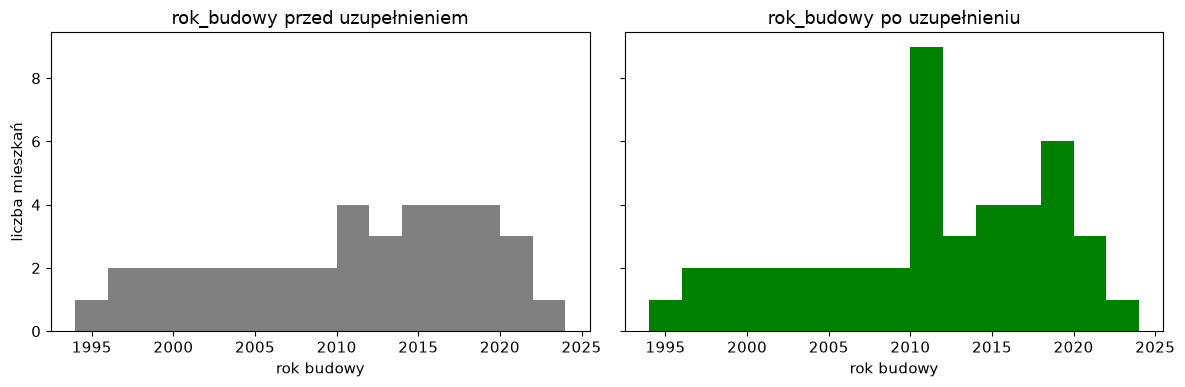

In [28]:
# TODO
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kolumny_porownania = ["powierzchnia", "rok_budowy", "cena_m2"]

# 1.
for kolumna in kolumny_porownania:
    porownanie = pd.DataFrame({
        "przed": surowe[kolumna].describe(),
        "po": mieszkania[kolumna].describe()
    })
    print("kolumna:", kolumna)
    print(porownanie.round(1))
    print()

# 2.
przedzialy_lat = np.arange(1994, 2026, 2)
fig, osie = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

osie[0].hist(surowe["rok_budowy"].dropna(), bins=przedzialy_lat, color="gray")
osie[0].set_title("rok_budowy przed uzupełnieniem")

osie[1].hist(mieszkania["rok_budowy"], bins=przedzialy_lat, color="green")
osie[1].set_title("rok_budowy po uzupełnieniu")

for ax in osie:
    ax.set_xlabel("rok budowy")
osie[0].set_ylabel("liczba mieszkań")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* …  
nie, rozkłady zmieniły się tylko trochę. Średnie są prawie takie same, a w `rok_budowy` odchylenie standardowe lekko spadło, bo braki dostały wartość mediany

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `N/A`, `brak`, `0` | 9 | `cena_total / cena_m2` | znamy prawdziwą wartość |
| `cena_m2` | `-1`, `-999` | 2 | `cena_total / powierzchnia` | znamy prawdziwą wartość |
| `rok_budowy` | `NA`, `brak` | 7 | mediana wg `stan` | stan zależy od wieku budynku |
| `pietro` | `brak`, `-999` | 3 | `liczba_pieter // 2` | piętro musi istnieć w budynku |
| `parking` | `?` | 5 | `"nieznane"` | dominanta zawyża liczbę `Tak` |
| `balkon` | `?` | 3 | `"nieznane"` | dominanta zawyża liczbę `Tak` |
| `stan` | `很好` | 1 | `Bardzo dobry` | to po chińsku „bardzo dobrze” |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [29]:
# TODO
surowy_rok = surowe["rok_budowy"]
cena = mieszkania["cena_m2"]  # cena_m2 po odtworzeniu, bez braków

warianty_roku = {
    "bez braków": surowy_rok,
    "mediana całościowa": surowy_rok.fillna(surowy_rok.median()),
    "mediana wg miasta": surowy_rok.fillna(surowy_rok.groupby(mieszkania["miasto"]).transform("median")),
    "mediana wg stanu": surowy_rok.fillna(surowy_rok.groupby(mieszkania["stan"]).transform("median")),
}

korelacje = pd.Series({nazwa: rok.corr(cena) for nazwa, rok in warianty_roku.items()})
roznice = (korelacje - korelacje["bez braków"]).abs()
print("korelacje rok_budowy z cena_m2:\n", pd.DataFrame({"korelacja": korelacje, "zmiana": roznice}).round(3))

korelacje rok_budowy z cena_m2:
                     korelacja  zmiana
bez braków              0.709   0.000
mediana całościowa      0.678   0.031
mediana wg miasta       0.710   0.001
mediana wg stanu        0.697   0.011


*Twoja odpowiedź:* …  
Najmniej zmienia korelację mediana w grupach według miasta. Mediana według stanu zmienia ją o ok. 0,01, a mediana całościowa najbardziej, bo wpisuje ten sam rok mieszkaniom o bardzo różnych cenach i osłabia zależność. Różnice są małe, bo braków jest tylko 7, ale widać, że uzupełnianie jedną wartością dla wszystkich zaniża korelacje.